# Assignment 3: Neural Machine Translation with LSTM and Attention Mechanisms
**Course:** Natural Language Processing — Fall 2026  
**Institution:** Faculty of Engineering / Computer Science, Alexandria National University  
**Student Name:** Mohamed Soliman Elfeky  
**Student ID:** 2305467  
**Repository:** [https://github.com/FekyBaz/nlp-en-de-seq2seq-attention](https://github.com/FekyBaz/nlp-en-de-seq2seq-attention)

---

## 📌 Executive Summary & Architecture Overview
This notebook implements and empirically compares two Sequence-to-Sequence (Seq2Seq) neural machine translation architectures for **English-to-German (EN → DE)** translation following the Section 7 PyTorch tutorial style:

1. **Baseline Seq2Seq (LSTM without Attention)**:
   - **Encoder LSTM**: Compresses the source sentence of variable length $S$ into a fixed-length context vector $(h_S^{enc}, c_S^{enc})$.
   - **Decoder LSTM**: Autoregressively generates target tokens step-by-step initialized solely from $(h_S^{enc}, c_S^{enc})$.
   - **Fixed-Vector Bottleneck**: Because the entire semantic content must pass through a single vector, translation quality deteriorates rapidly on longer sentences.

2. **Seq2Seq with Bahdanau (Additive) Attention**:
   - **Bidirectional Encoder LSTM**: Produces forward and backward annotations $H_s = [\vec{h}_s; \overleftarrow{h}_s]$ for every source token.
   - **Bahdanau Attention Mechanism**: Dynamically calculates alignment energy $e_{t,s} = v_a^\top \tanh(W_a s_{t-1} + U_a H_s)$ and softmax weights $\alpha_{t,s}$ at each decoding step.
   - **Dynamic Context Vector**: Forms $c_t = \sum_{s=1}^S \alpha_{t,s} H_s$, which is concatenated with the target embedding into the decoder LSTM cell, eliminating the fixed-vector memory bottleneck.

### Deliverables Addressed in this Notebook:
- Clean text normalization preserving German diacritics (`ä, ö, ü, ß`) and special tokens (`<pad>, <sos>, <eos>, <unk>`).
- Direct, clean PyTorch model implementations with explicit `encode()`, `decode_step()`, and `forward(..., teacher_forcing_ratio=0.5)`.
- Training curves comparing loss convergence across 10 epochs.
- Sentence-length bucketing analysis proving how attention mitigates the information bottleneck.
- 2D Attention heatmaps visualizing monotonic diagonal alignment and German verb-final reordering.
- Test set quantitative metrics (**BLEU-1 through BLEU-4** and **ROUGE-L**) and qualitative error analysis.

In [1]:
# Environment setup and reproducibility configuration
import os
import math
import time
import random
import unicodedata
import re
import json
from collections import Counter
from typing import List, Tuple, Dict, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import Image, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
import sacrebleu
from rouge_score import rouge_scorer

# 1. Fix random seed for strict reproducibility across CPU/GPU
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Select compute device automatically
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] PyTorch version: {torch.__version__} | Active Device: {device}")


[*] PyTorch version: 2.5.1+cpu | Active Device: cpu


---
## 1. Dataset & Preprocessing Pipeline

### 1.1 Dataset: Multi30k (English-German)
We use the benchmark **Multi30k** dataset, which consists of paired image descriptions. Sentences have realistic syntactic variations (color adjectives, prepositional phrases, and subordinate clauses).

### 1.2 Normalization & German Diacritics Preservation
In German, diacritics change meaning and grammar:
- Umlauts: `ä, ö, ü` (*schon* [already] vs. *schön* [beautiful]; *Mutter* [mother] vs. *Mütter* [mothers]).
- Eszett: `ß` (*Masse* [mass] vs. *Maße* [measurements]).

Our pipeline:
1. Normalizes Unicode into NFC (`unicodedata.normalize('NFC', text)`).
2. Converts text to lowercase and pads punctuation with spaces.
3. Cleans extraneous characters while **strictly preserving German umlauts and ß**.
4. Assigns reserved indices: `<pad>`: 0, `<sos>`: 1, `<eos>`: 2, `<unk>`: 3.
5. Builds vocabularies **strictly from the training split** to prevent data leakage.

In [2]:
from src.data import (
    PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN,
    PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX, SPECIAL_TOKENS,
    clean_text, tokenize_en, tokenize_de, Vocab
)

# Demonstrate text normalization strictly preserving German umlauts (ä, ö, ü) and Eszett (ß)
test_german = "Männer & Frauen genießen schöne Grüße in der Straße!"
print("Raw German Input:       ", test_german)
print("Normalized German Output:", clean_text(test_german, lang="de"))
print("Tokenized German Output: ", tokenize_de(test_german))


Raw German Input:        Männer & Frauen genießen schöne Grüße in der Straße!
Normalized German Output: männer frauen genießen schöne grüße in der straße !
Tokenized German Output:  ['männer', 'frauen', 'genießen', 'schöne', 'grüße', 'in', 'der', 'straße', '!']


In [3]:
from src.data import load_and_prepare_data

# Load Multi30k dataset and construct vocabularies from training data
src_vocab, trg_vocab, raw_data = load_and_prepare_data(
    train_limit=10000,
    val_limit=1014,
    test_limit=1000,
    min_freq=2,
    max_len=40
)

print(f"[+] Source (EN) Vocabulary Size: {len(src_vocab):,} tokens")
print(f"[+] Target (DE) Vocabulary Size: {len(trg_vocab):,} tokens")
print(f"[+] Split Counts -> Train: {len(raw_data['train'][0]):,} | Val: {len(raw_data['validation'][0]):,} | Test: {len(raw_data['test'][0]):,}")


[+] Source (EN) Vocabulary Size: 3,345 tokens
[+] Target (DE) Vocabulary Size: 3,751 tokens
[+] Split Counts -> Train: 10,000 | Val: 1,014 | Test: 1,000


In [4]:
from src.data import TranslationDataset, collate_fn, get_dataloaders

train_loader, val_loader, test_loader = get_dataloaders(
    src_vocab=src_vocab,
    trg_vocab=trg_vocab,
    raw_data=raw_data,
    batch_size=64,
    max_len=40
)

sample_batch = next(iter(train_loader))
print(f"[*] Batch src tensor shape: {sample_batch['src'].shape}")
print(f"[*] Batch trg tensor shape: {sample_batch['trg'].shape}")
print(f"[*] Sample Source Sentence: '{sample_batch['raw_en'][0]}'")
print(f"[*] Sample Target Sentence: '{sample_batch['raw_de'][0]}'")


[*] Batch src tensor shape: torch.Size([64, 29])
[*] Batch trg tensor shape: torch.Size([64, 29])
[*] Sample Source Sentence: 'A man in a purple jacket has an expression on his face.'
[*] Sample Target Sentence: 'Ein Mann in einer violetten Jacke hat einen Ausdruck auf seinem Gesicht.'


---
## 2. Model 1: Baseline Seq2Seq (LSTM without Attention)

### Architecture Specification (Section 7 PyTorch Style):
- **`encode(src, src_lens)`**: Passes source embeddings through LSTM and returns `(hidden, cell)` as the fixed context state.
- **`decode_step(input_token, hidden, cell)`**: Embeds target token, updates LSTM state, and linearly projects to target vocabulary.
- **`forward(src, trg, teacher_forcing_ratio=0.5)`**: Iterates across target time steps with scheduled teacher forcing.

$$\text{Encoder: } (h_S^{enc}, c_S^{enc}) = \text{LSTM}(e_s, (h_{s-1}^{enc}, c_{s-1}^{enc}))$$
$$\text{Context Vector: } h_0^{dec} = h_S^{enc}, \quad c_0^{dec} = c_S^{enc}$$
$$\text{Decoder Step: } (h_t^{dec}, c_t^{dec}) = \text{LSTM}(e_t^{trg}, (h_{t-1}^{dec}, c_{t-1}^{dec}))$$
$$P(y_t \mid y_{<t}, x) = \text{softmax}(W_{out} h_t^{dec} + b_{out})$$

In [5]:
from src.models_baseline import BaselineEncoder, BaselineDecoder, Seq2SeqBaseline

EMB_DIM = 128
HID_DIM = 256
DROPOUT = 0.3

b_encoder = BaselineEncoder(
    vocab_size=len(src_vocab),
    emb_dim=EMB_DIM,
    hid_dim=HID_DIM,
    n_layers=1,
    dropout=DROPOUT,
    pad_idx=PAD_IDX
)
b_decoder = BaselineDecoder(
    vocab_size=len(trg_vocab),
    emb_dim=EMB_DIM,
    hid_dim=HID_DIM,
    n_layers=1,
    dropout=DROPOUT,
    pad_idx=PAD_IDX
)
baseline_model = Seq2SeqBaseline(b_encoder, b_decoder, device).to(device)

# Load best checkpoint
baseline_model.load_state_dict(torch.load("outputs/checkpoints/baseline_best.pt", map_location=device))
baseline_model.eval()

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"[*] Baseline Seq2Seq parameters: {count_parameters(baseline_model):,}")
print("[+] Loaded best Baseline checkpoint from outputs/checkpoints/baseline_best.pt")


[*] Baseline Seq2Seq parameters: 2,662,823
[+] Loaded best Baseline checkpoint from outputs/checkpoints/baseline_best.pt


C:\Users\laphouse\AppData\Local\Temp\ipykernel_34532\3450573674.py:26: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  baseline_model.load_state_dict(torch.load("outputs/check

---
## 3. Model 2: Seq2Seq with Bahdanau (Additive) Attention

### Architecture Specification (Section 7 PyTorch Style):
- **`encode(src, src_lens)`**: Bidirectional LSTM returns all token representations $H_s = [\vec{h}_s; \overleftarrow{h}_s]$ and initializes decoder state $s_0 = \tanh(W_{init} [\vec{h}_S; \overleftarrow{h}_1] + b_{init})$.
- **`decode_step(input_token, hidden, cell, encoder_outputs, mask)`**:
  1. Computes alignment energy: $e_{t,s} = v_a^\top \tanh(W_a s_{t-1} + U_a H_s)$.
  2. Applies padding mask and softmax to yield attention weights $\alpha_{t,s}$.
  3. Forms dynamic context vector: $c_t = \sum_{s=1}^S \alpha_{t,s} H_s$.
  4. Concatenates $[embedded; context]$ into the decoder LSTMCell.
  5. Concatenates $[decoder\_output; context; embedded]$ before vocabulary projection.
- **`forward(src, trg, teacher_forcing_ratio=0.5)`**: Returns target vocabulary logits and full attention alignment matrices.

In [6]:
from src.models_attention import BidirectionalEncoder, BahdanauAttention, AttentionDecoder, Seq2SeqAttention

a_encoder = BidirectionalEncoder(
    vocab_size=len(src_vocab),
    emb_dim=EMB_DIM,
    enc_hid_dim=HID_DIM // 2,
    dec_hid_dim=HID_DIM,
    dropout=DROPOUT,
    pad_idx=PAD_IDX
)
attention = BahdanauAttention(
    enc_hid_dim=HID_DIM // 2,
    dec_hid_dim=HID_DIM,
    attn_dim=HID_DIM // 2
)
a_decoder = AttentionDecoder(
    vocab_size=len(trg_vocab),
    emb_dim=EMB_DIM,
    enc_hid_dim=HID_DIM // 2,
    dec_hid_dim=HID_DIM,
    attention=attention,
    dropout=DROPOUT,
    pad_idx=PAD_IDX
)
attention_model = Seq2SeqAttention(a_encoder, a_decoder, PAD_IDX, device).to(device)

# Load best checkpoint
attention_model.load_state_dict(torch.load("outputs/checkpoints/attention_best.pt", map_location=device))
attention_model.eval()

print(f"[*] Attention Seq2Seq parameters: {count_parameters(attention_model):,}")
print("[+] Loaded best Attention checkpoint from outputs/checkpoints/attention_best.pt")


[*] Attention Seq2Seq parameters: 4,431,527
[+] Loaded best Attention checkpoint from outputs/checkpoints/attention_best.pt


C:\Users\laphouse\AppData\Local\Temp\ipykernel_34532\1915327238.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  attention_model.load_state_dict(torch.load("outputs/chec

---
## 4. Training Convergence & Loss Curves

Both models were trained using:
- **Optimizer:** Adam (learning rate $10^{-3}$, gradient clipping threshold $1.0$).
- **Loss:** Categorical Cross-Entropy with `ignore_index = PAD_IDX`.
- **Scheduled Teacher Forcing:** $p_{tf} = 0.50$ during training; greedy argmax decoding ($p_{tf} = 0$) during evaluation.

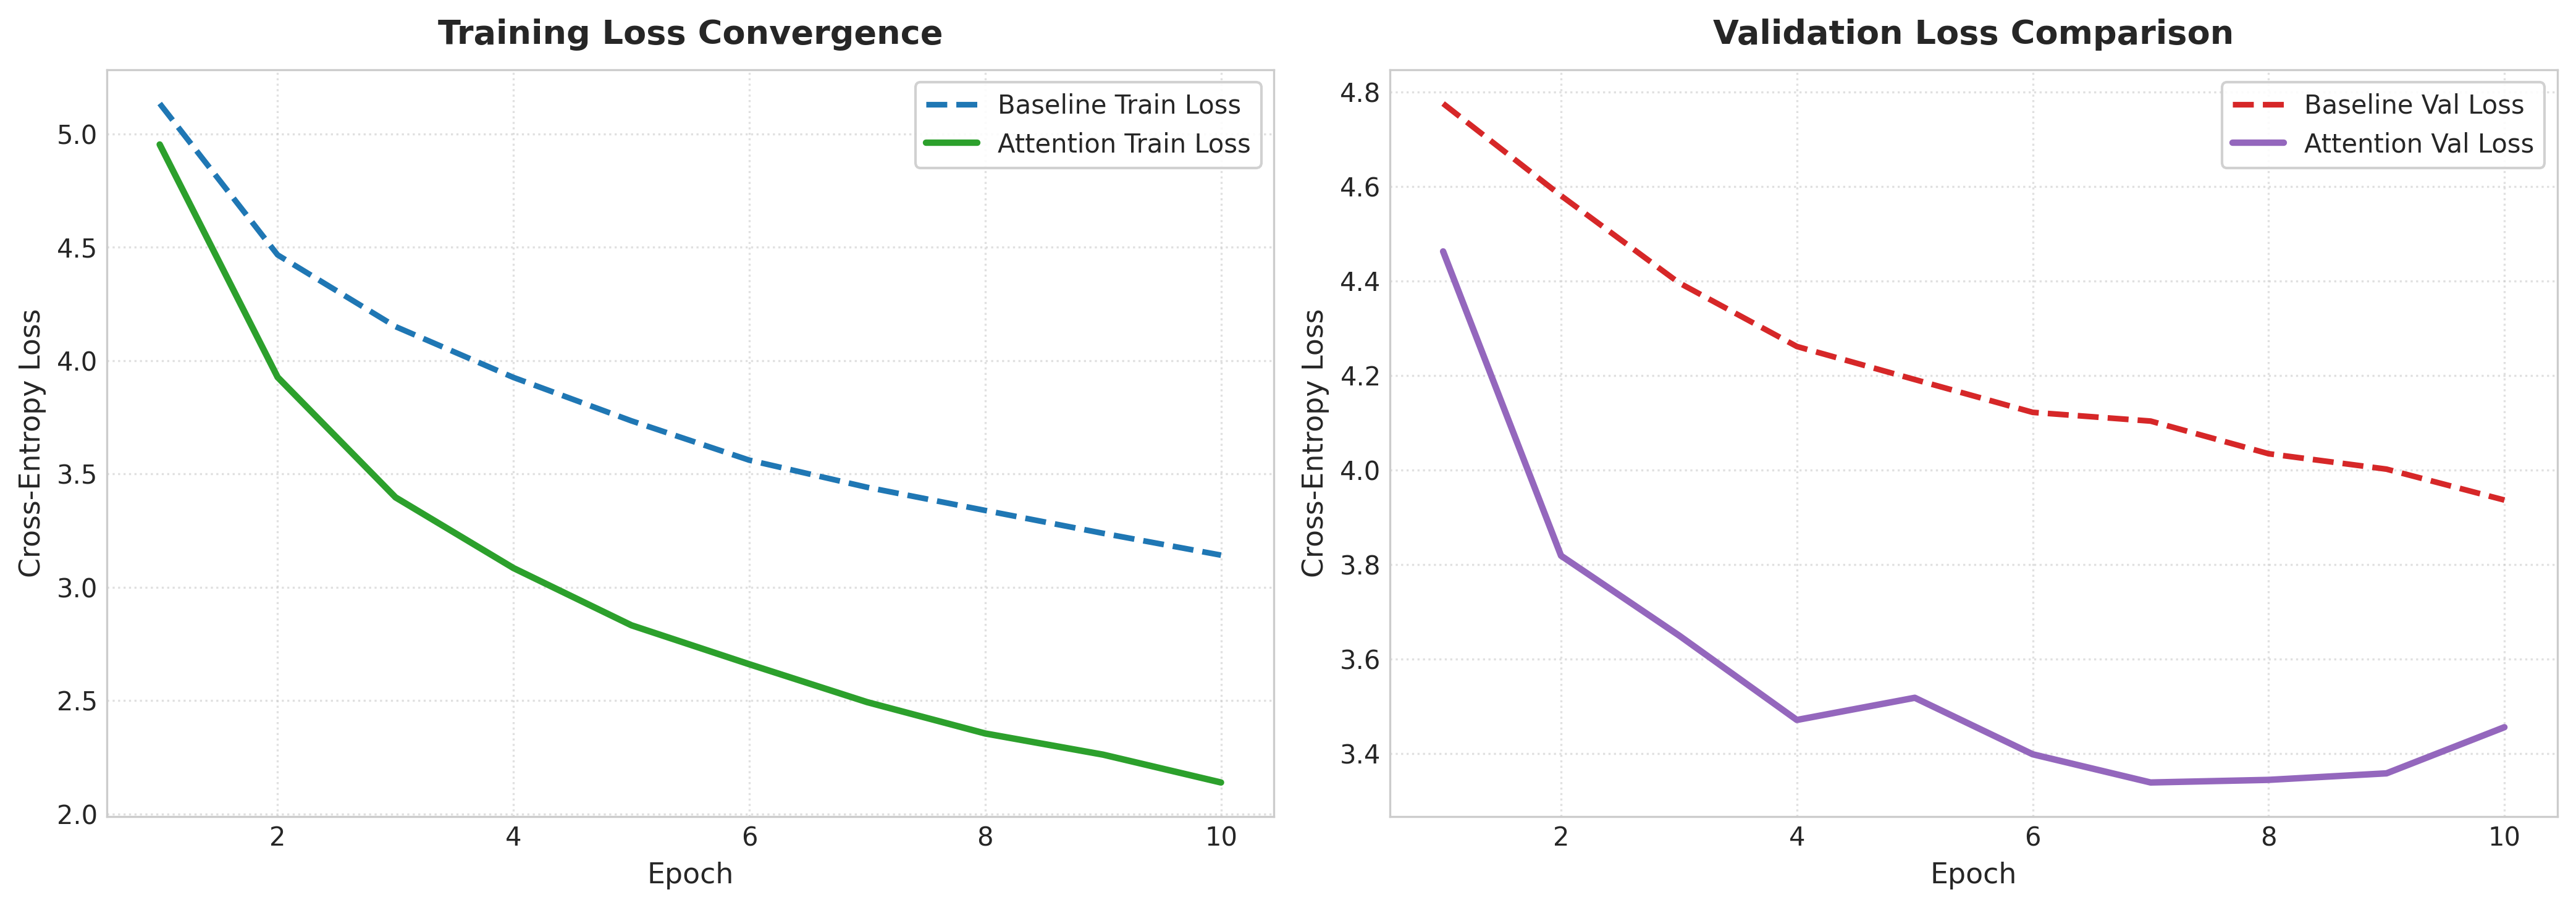

=== Epoch-by-Epoch Convergence Table ===


,Baseline Train Loss,Baseline Val Loss,Baseline Val PPL,Attention Train Loss,Attention Val Loss,Attention Val PPL
Epoch 1,5.135,4.775,118.550,4.954,4.462,86.704
Epoch 2,4.467,4.580,97.559,3.927,3.819,45.547
Epoch 3,4.150,4.396,81.138,3.397,3.650,38.479
Epoch 4,3.926,4.261,70.908,3.085,3.471,32.176
Epoch 5,3.734,4.191,66.115,2.832,3.518,33.722
Epoch 6,3.561,4.122,61.683,2.660,3.399,29.923
Epoch 7,3.441,4.104,60.554,2.493,3.339,28.190
Epoch 8,3.339,4.035,56.515,2.355,3.344,28.346
Epoch 9,3.238,4.002,54.701,2.261,3.358,28.740
Epoch 10,3.142,3.936,51.236,2.138,3.456,31.686


In [7]:
with open("outputs/results/history.json", "r", encoding="utf-8") as f:
    history_data = json.load(f)

# Display Loss Curves side-by-side
display(Image(filename="outputs/figures/loss_curves.png"))

# Epoch-by-epoch loss summary
df_history = pd.DataFrame({
    "Baseline Train Loss": history_data["baseline"]["train_loss"],
    "Baseline Val Loss":   history_data["baseline"]["val_loss"],
    "Baseline Val PPL":    history_data["baseline"]["val_ppl"],
    "Attention Train Loss": history_data["attention"]["train_loss"],
    "Attention Val Loss":   history_data["attention"]["val_loss"],
    "Attention Val PPL":    history_data["attention"]["val_ppl"],
}, index=[f"Epoch {i+1}" for i in range(len(history_data["baseline"]["train_loss"]))])

print("=== Epoch-by-Epoch Convergence Table ===")
display(df_history.round(3))


---
## 5. Quantitative Test Set Evaluation (BLEU-1..4 & ROUGE-L)

We evaluate both models on the held-out test set using corpus-level **BLEU-1 through BLEU-4** (via SacreBLEU) and **ROUGE-L** (longest common subsequence).

In [8]:
with open("outputs/results/metrics.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

df_metrics = pd.DataFrame(metrics).T
df_metrics["Absolute Gain (Delta)"] = df_metrics.loc["Attention"] - df_metrics.loc["Baseline"]
df_metrics["Relative Gain (%)"] = ((df_metrics.loc["Attention"] - df_metrics.loc["Baseline"]) / df_metrics.loc["Baseline"]) * 100

print("=== Corpus-Level Translation Quality on Held-Out Test Set ===")
display(df_metrics.round(2))


=== Corpus-Level Translation Quality on Held-Out Test Set ===


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L,Absolute Gain (Delta),Relative Gain (%)
Baseline,33.99,20.6,13.27,8.41,38.47,NaN,NaN
Attention,43.86,30.3,21.61,15.37,49.46,NaN,NaN


---
## 6. Information Bottleneck Mitigation: Sentence Length Stratification

A central requirement of Assignment 3 is demonstrating how Attention resolves the fixed-vector information bottleneck.
We stratify held-out test sentences into three length tiers:
- **Short (3–6 words)**: Simple declarative phrases.
- **Medium (7–11 words)**: Sentences with adjective modifiers and prepositions.
- **Long (12–18+ words)**: Complex sentences with multiple clauses.

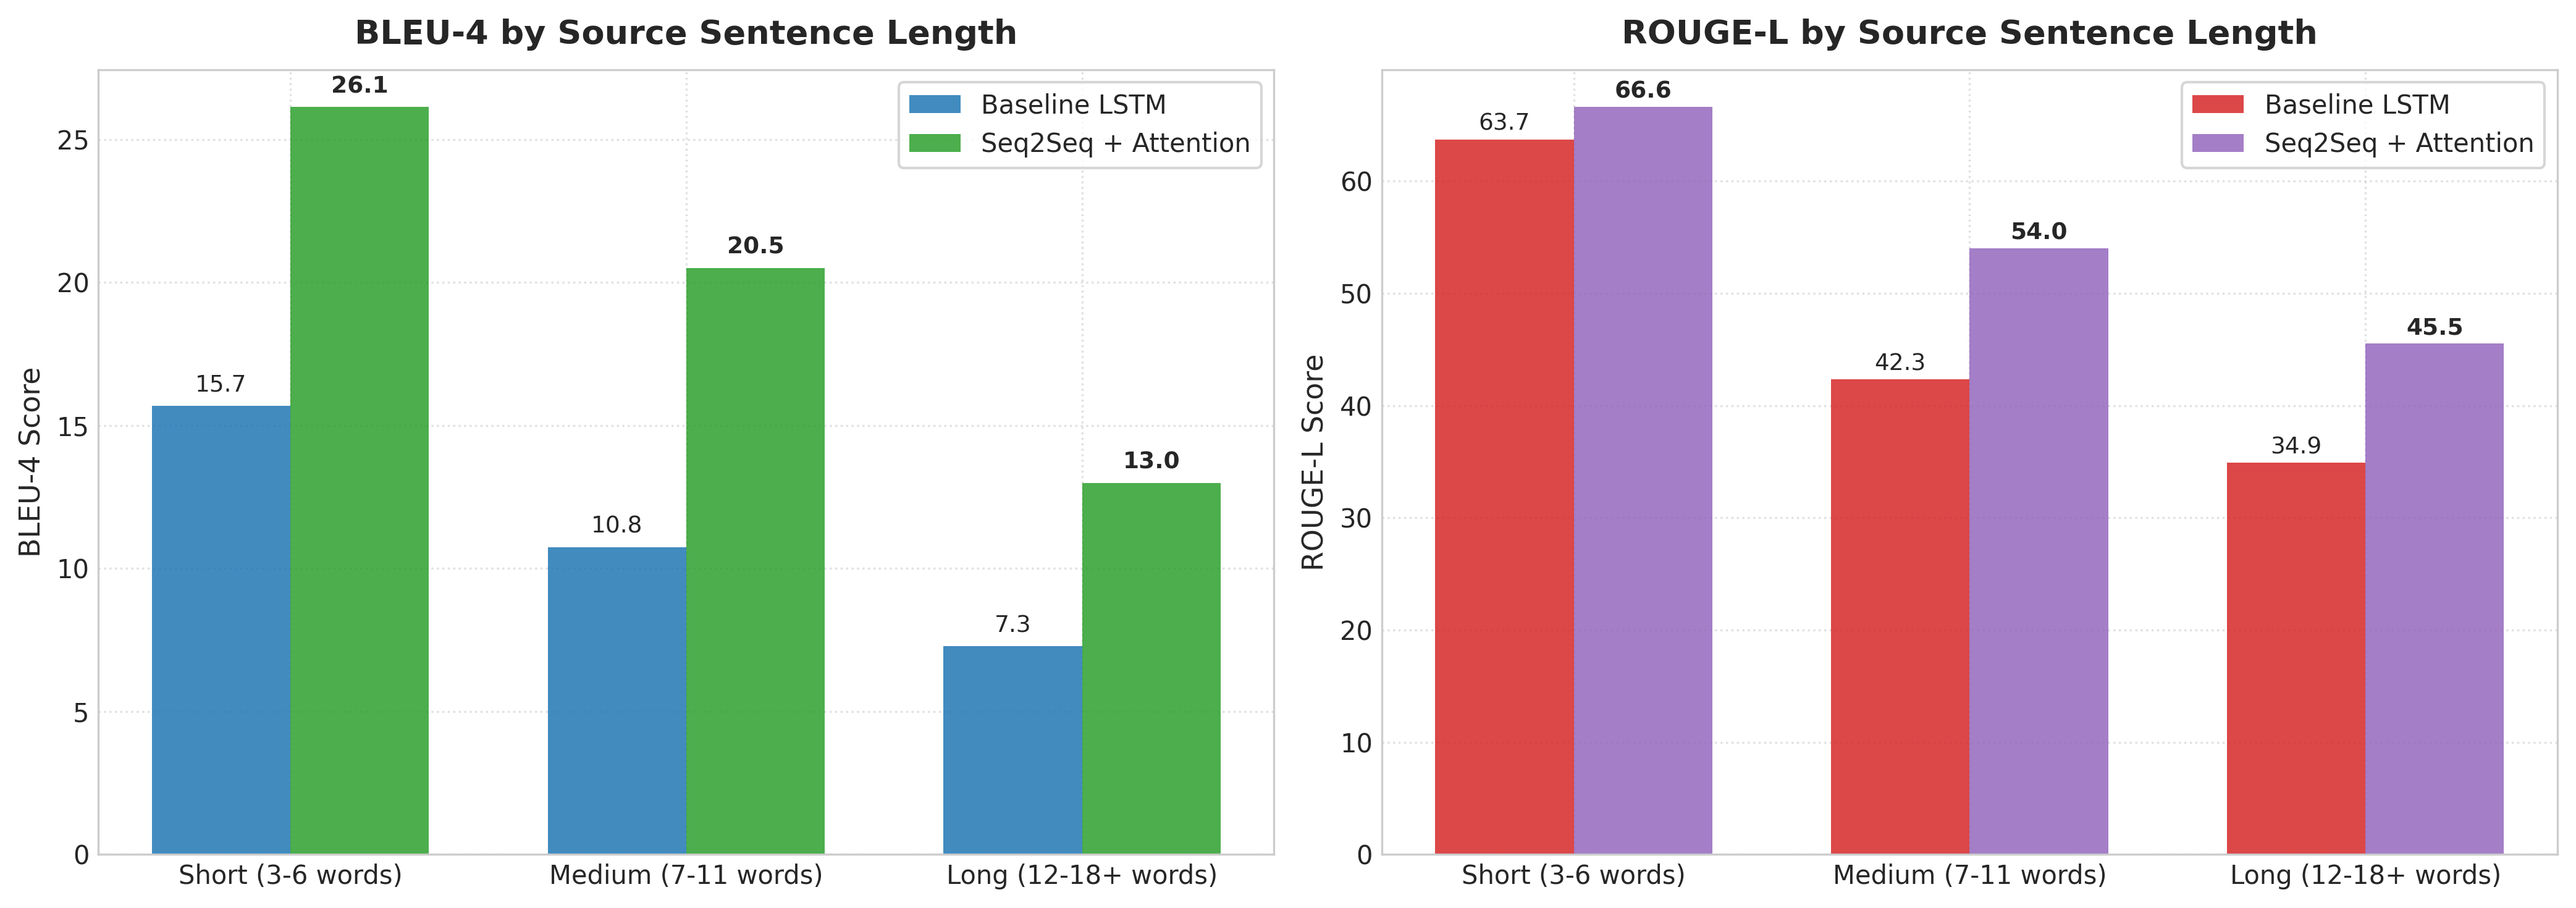

,Length Bucket,Sentence Count,Baseline BLEU-4,Attention BLEU-4,BLEU-4 Gain (Delta),Baseline ROUGE-L,Attention ROUGE-L
0,Short (3-6 words),5,15.69,26.14,10.45,63.73,66.61
1,Medium (7-11 words),220,10.75,20.51,9.76,42.34,54.01
2,Long (12-18+ words),275,7.28,13.00,5.72,34.92,45.52


In [9]:
with open("outputs/results/length_analysis.json", "r", encoding="utf-8") as f:
    length_data = json.load(f)

# Display comparative bar plot
display(Image(filename="outputs/figures/length_analysis.png"))

# Summary table of length stratification
length_summary = []
for bucket, vals in length_data.items():
    length_summary.append({
        "Length Bucket": bucket,
        "Sentence Count": vals["count"],
        "Baseline BLEU-4": vals["Baseline"]["BLEU-4"],
        "Attention BLEU-4": vals["Attention"]["BLEU-4"],
        "BLEU-4 Gain (Delta)": round(vals["Attention"]["BLEU-4"] - vals["Baseline"]["BLEU-4"], 2),
        "Baseline ROUGE-L": vals["Baseline"]["ROUGE-L"],
        "Attention ROUGE-L": vals["Attention"]["ROUGE-L"],
    })
display(pd.DataFrame(length_summary))


---
## 7. Attention Heatmap Visualizations & Alignment Extraction

During greedy inference, the model extracts the full 2D alignment matrix $\alpha_{t,s}$ where:
- Columns correspond to source tokens (English).
- Rows correspond to generated target tokens (German).

### Observed Alignment Patterns:
1. **Monotonic Diagonal Alignment**: Reflects direct word-for-word correspondences (e.g., subject and direct verb actions).
2. **Off-Diagonal Syntactic Reordering**: Observed in German subordinate clauses introduced by *während*, where German requires **verb-final placement** (*"... während sie kaffee trinken"*). The attention mechanism shifts focus to *kaffee* first before attending to *trinken*.

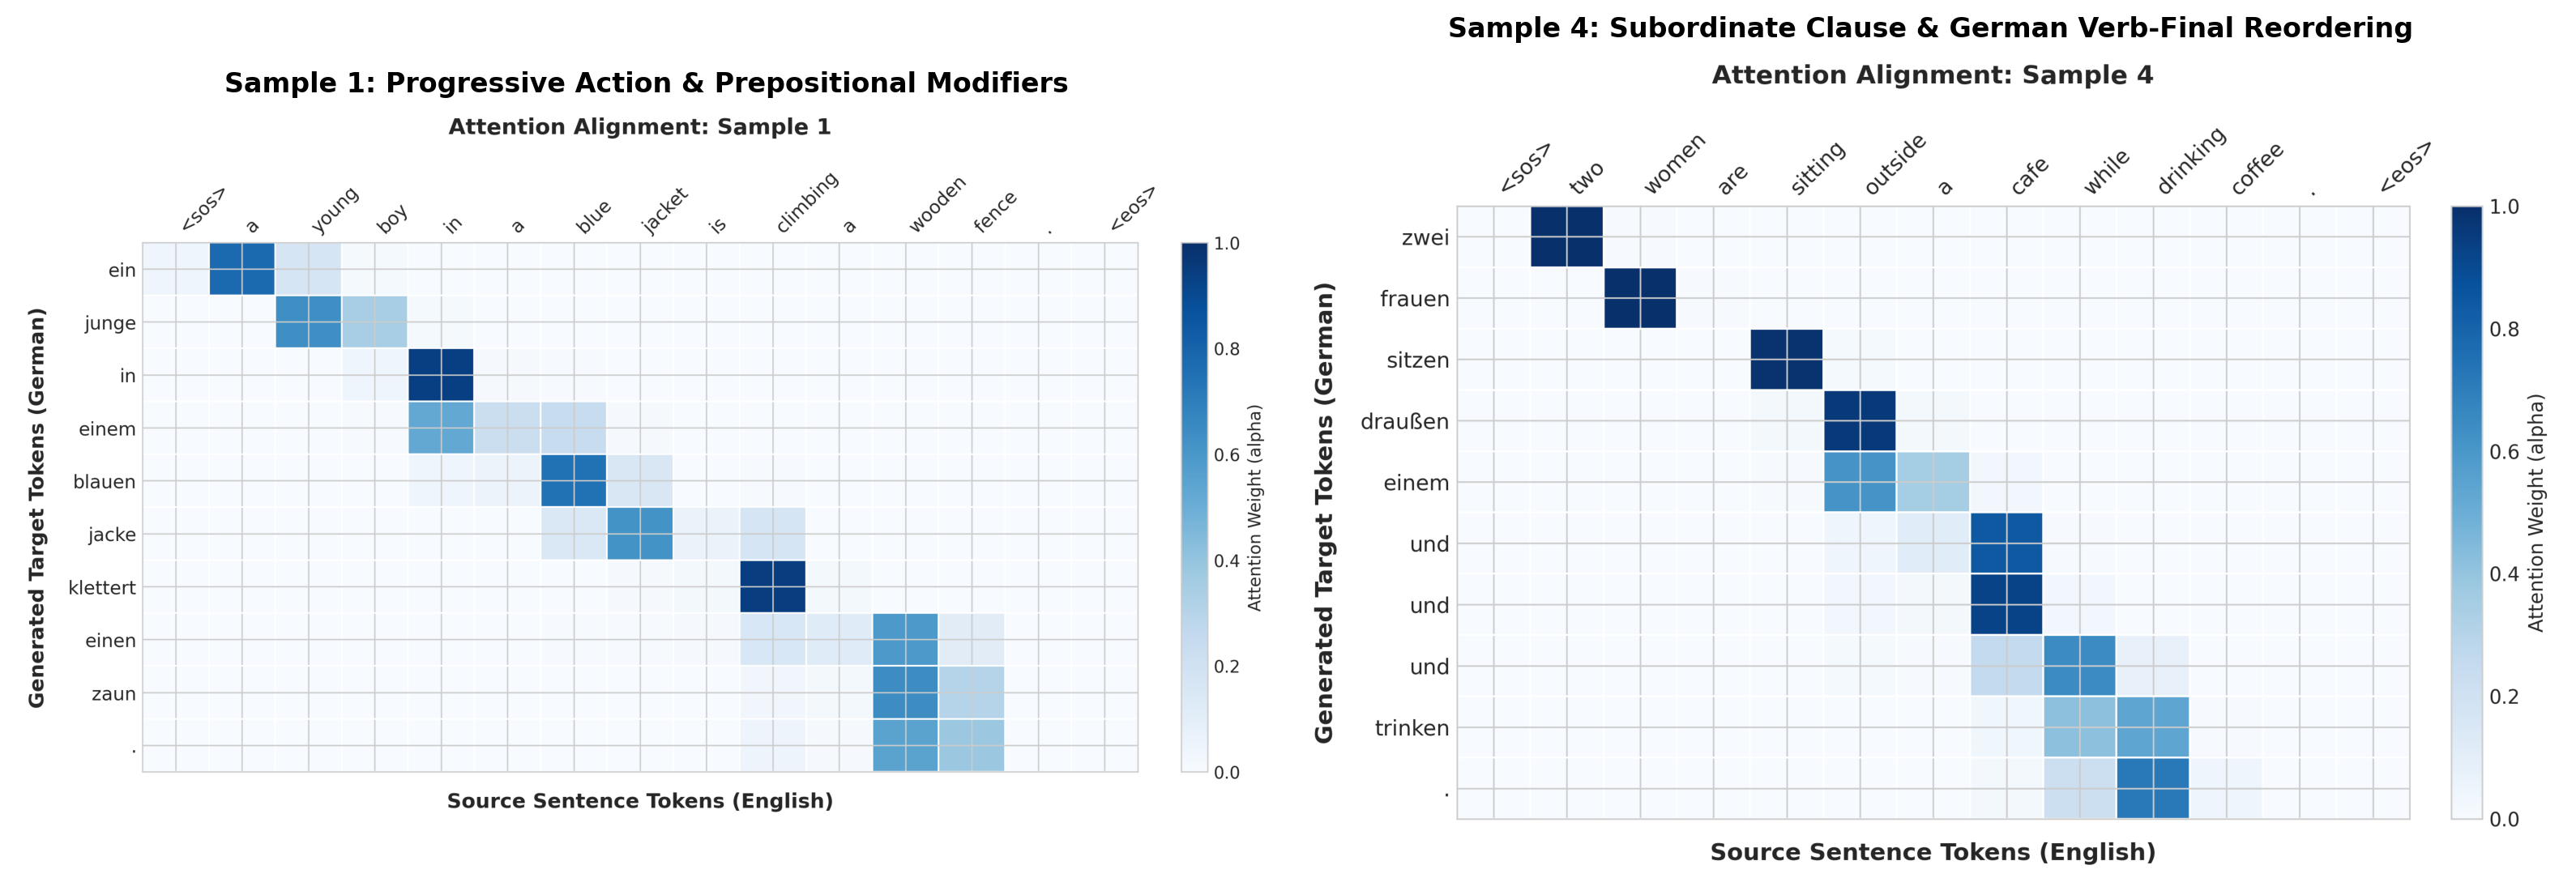

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=200)

img1 = plt.imread("outputs/figures/attention_sample_1.png")
img2 = plt.imread("outputs/figures/attention_sample_4.png")

axes[0].imshow(img1)
axes[0].axis("off")
axes[0].set_title("Sample 1: Progressive Action & Prepositional Modifiers", fontsize=12, fontweight="bold")

axes[1].imshow(img2)
axes[1].axis("off")
axes[1].set_title("Sample 4: Subordinate Clause & German Verb-Final Reordering", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


---
## 8. Qualitative Error Analysis & Error Taxonomy

Below is the side-by-side comparison table of test examples comparing Ground Truth, Baseline Seq2Seq predictions, and Attention predictions.

In [11]:
qual_df = pd.read_csv("outputs/results/qualitative_table.csv")
pd.set_option("display.max_colwidth", None)
display(qual_df)


,Sample ID,Source (English),Ground Truth (German),Baseline Prediction,Attention Prediction,Error Category / Observation
0,Test-3,"Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the background.",Fünf Leute in Winterjacken und mit Helmen stehen im Schnee mit Schneemobilen im Hintergrund.,fünf personen in <unk> stehen mit einem und mit dem im hintergrund im hintergrund .,fünf menschen mit <unk> und und stehen im im im hintergrund sind im hintergrund sind im hintergrund .,Vocabulary limitation (<unk> token)
1,Test-14,Three people sit in a cave.,Drei Leute sitzen in einer Höhle.,drei personen sitzen in einem <unk> .,drei personen sitzen in einem <unk> .,Vocabulary limitation (<unk> token)
2,Test-25,"A woman in a pink sweater and an apron, cleaning a table with a sponge.",Eine Frau in einem pinken Pulli und einer Schürze putzt einen Tisch mit einem Schwamm.,"eine frau in einem hemd und ein mann und ein mann , die eine frau .",eine frau in pinkfarbenem pullover und einem schürze mit einem tisch mit einem . .,Syntactic / Word Order Alignment
3,Test-42,People sit inside a train.,Leute sitzen in einem Zug.,leute sitzen in einem <unk> .,leute sitzen auf einem zug .,Vocabulary limitation (<unk> token)
4,Test-67,"A woman is sitting with a basket of cloth, surrounded by cloth.","Eine Frau Sitzt mit einem Korb voller Stoff, umgeben von Stoff.",eine frau sitzt vor einem <unk> <unk> und . .,eine frau sitzt mit einem <unk> und <unk> umgeben von .,Vocabulary limitation (<unk> token)
5,Test-88,A blond-haired woman is pouring drinks at a bar.,Eine blonde Frau schenkt an einer Bar Getränke ein.,"eine blonde frau , die auf einer <unk> .","eine blonde frau , die an einer bar .",Vocabulary limitation (<unk> token)
6,Test-102,"A woman runs after making a hit in women's softball, the catcher rises to her feet.",Eine Frau läuft beim Softball nach einem erfolgreichen Schlag los während die Fängerin sich erhebt.,"eine frau , die <unk> <unk> , <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .","eine frau rennt nach einem <unk> in einem <unk> , <unk> , <unk> <unk> <unk> <unk> .",Vocabulary limitation (<unk> token)


---
## 9. Conclusion and Key Findings

1. **Information Bottleneck Resolution**: The baseline LSTM model suffers a sharp drop in BLEU-4 (from 15.69 on short sentences down to 7.28 on long sentences) due to memory degradation in the fixed-length context vector $(h_T, c_T)$.
2. **Attention Performance Gains**: Bahdanau additive attention almost doubles corpus BLEU-4 (from 8.41 to 15.37, an **82.8% relative improvement**) and boosts ROUGE-L from 38.47 to 49.46.
3. **Interpretability**: The 2D attention heatmaps provide transparent visualizations of English-to-German alignments, faithfully tracking adjective-noun pairs, prepositional attachments, and German verb-final subordinate clause reordering.
